# 11b — A residual on the controlled variable as the drift detector (System I, N3)

**Why.** Notebook 11 shows that the production posterior is confidently wrong under an unmodelled +2 K temperature-sensor drift (Sc7: β̂ biased by −0.395, coverage 0.002):
the posterior extrapolates silently. The practitioner needs a check that does not depend on the posterior. In closed loop with integral action the controlled temperature sits at the setpoint,
so a measured mean temperature away from T_sp by more than the sensor noise is either a sensor offset or a loss of control (valve saturation).

**Statistic (fixed before running; runbook §2f row c2).** z_T = (mean over the 60-min window of the measured T − T_sp) / (0.2 K/√120) with the N3 sensor sd of 0.2 K (the window-mean noise bound, 0.0183 K).
Computed for Sc1–Sc5 and Sc7 on **D1** (50 per scenario) and **L1** (1,000 per scenario; same generator and seed base 3 800 000 as notebook 11). Reported per scenario: median, 5–95% range, and the
detection rate at |z_T| > 5; the same split by saturation (a window is saturated if more than 50% of its samples have Qc ≥ 395 L/min); a **guarded** rule (flag only unsaturated windows); the false-positive rate of the guarded rule in Sc1–Sc5 at |z_T| > 5
and at the 99th percentile of the unsaturated Sc1–Sc5 |z_T|; the detection rate of Sc7 at those thresholds; the AUC of |z_T| for Sc7 against Sc1–Sc5 (unsaturated windows).
**Checks:** all finite; D1 and L1 agree on the Sc7 detection rate within 3 binomial standard errors. No decision rule.


In [1]:
import os, sys, time
from pathlib import Path
import numpy as np, pandas as pd
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_phase3
importlib.reload(ws_phase3); P3 = ws_phase3
R = ROOT / "results"; T0 = time.time()
TSP, SD = 312.5, 0.2 / np.sqrt(120.0)
SCN = {1: "Sc1", 2: "Sc2", 3: "Sc3", 4: "Sc4", 5: "Sc5", 7: "Sc7"}
d1 = P3.load_d1(); dL = P3.generate_d1(n_rep=1000, seed_base=3_800_000)
def stat(d):
    x = d["x"]; z = (x[:, :, 1].mean(1) - TSP) / SD; sat = (x[:, :, 3] >= 395).mean(1) > 0.5
    return pd.DataFrame(dict(scenario=[SCN[int(s)] for s in d["scenario_id"]], z=z, sat=sat))
S = {"D1": stat(d1), "L1": stat(dL)}
for k, v in S.items():
    assert np.isfinite(v.z).all(); print(k, len(v), "windows")


D1 300 windows
L1 6000 windows


## 1. Distribution of z_T per scenario and the detection rate at |z_T| > 5

In [2]:
rows = []
for dn, df in S.items():
    for sc in SCN.values():
        g = df[df.scenario == sc]; u = g[~g.sat]; s_ = g[g.sat]
        rows.append(dict(data=dn, scenario=sc, n=len(g), frac_saturated=g.sat.mean(), z_median=g.z.median(), z_p05=g.z.quantile(.05), z_p95=g.z.quantile(.95),
                         rate_gt5_all=(g.z.abs() > 5).mean(), rate_gt5_unsat=(u.z.abs() > 5).mean() if len(u) else np.nan,
                         rate_gt5_sat=(s_.z.abs() > 5).mean() if len(s_) else np.nan, n_unsat=len(u),
                         guarded_rate_gt5=((~g.sat) & (g.z.abs() > 5)).sum() / max((~g.sat).sum(), 1)))
tab = pd.DataFrame(rows); display(tab.round(3)); tab.to_csv(R / "11b_N3_zT_distribution.csv", index=False)


,data,scenario,n,frac_saturated,z_median,z_p05,z_p95,rate_gt5_all,rate_gt5_unsat,rate_gt5_sat,n_unsat,guarded_rate_gt5
0,D1,Sc1,50,0.300,0.389,-4.432,47.764,0.380,0.114,1.000,35,0.114
1,D1,Sc2,50,0.420,2.313,-3.895,74.531,0.480,0.103,1.000,29,0.103
2,D1,Sc3,50,0.080,-0.417,-4.662,16.640,0.180,0.109,1.000,46,0.109
3,D1,Sc4,50,0.320,1.258,-4.100,43.337,0.380,0.088,1.000,34,0.088
4,D1,Sc5,50,0.740,66.743,-2.270,146.308,0.780,0.154,1.000,13,0.154
5,D1,Sc7,50,0.380,109.667,106.228,182.007,1.000,1.000,1.000,31,1.000
6,L1,Sc1,1000,0.216,-0.581,-4.448,45.765,0.281,0.083,1.000,784,0.083
7,L1,Sc2,1000,0.390,1.412,-4.449,76.686,0.453,0.110,0.990,610,0.110
8,L1,Sc3,1000,0.178,-0.690,-5.154,35.833,0.271,0.113,1.000,822,0.113
9,L1,Sc4,1000,0.395,1.531,-4.444,73.443,0.458,0.111,0.990,605,0.111


## 2. Guarded rule: false positives in Sc1–Sc5 and detection of Sc7 at two thresholds (L1)

In [3]:
L = S["L1"]; U = L[~L.sat]
ref = U[U.scenario != "Sc7"].z.abs()
thr99 = float(ref.quantile(0.99))
out = []
for name, thr in (("5", 5.0), ("99th pct of unsaturated Sc1-Sc5 |z|", thr99), ("10", 10.0), ("20", 20.0)):
    fp = {sc: float((U[U.scenario == sc].z.abs() > thr).mean()) for sc in SCN.values() if sc != "Sc7"}
    det_u = float((U[U.scenario == "Sc7"].z.abs() > thr).mean())
    det_all = float((L[L.scenario == "Sc7"].z.abs() > thr).mean())
    out.append(dict(threshold=name, value=round(thr, 2), **{f"FP_{k}": v for k, v in fp.items()}, FP_pooled_Sc1_5=float((ref > thr).mean()),
                    Sc7_detect_unsaturated=det_u, Sc7_detect_all_windows=det_all))
guard = pd.DataFrame(out); display(guard.round(3)); guard.to_csv(R / "11b_N3_zT_guarded_rule.csv", index=False)
# AUC of |z| for Sc7 against Sc1-Sc5 in unsaturated windows (Mann-Whitney)
from scipy.stats import mannwhitneyu
a = U[U.scenario == "Sc7"].z.abs().values; b = ref.values
auc = mannwhitneyu(a, b).statistic / (len(a) * len(b))
print(f"AUC of |z_T| (Sc7 vs Sc1-Sc5, unsaturated, L1): {auc:.4f} (n = {len(a)} vs {len(b)})")
# sign of z in Sc7 saturated windows
Sg = L[(L.scenario == "Sc7") & L.sat]
print(f"Sc7 saturated windows: n = {len(Sg)}; |z_T| > 5 in {(Sg.z.abs() > 5).mean():.3f}; median z_T {Sg.z.median():+.1f}")


,threshold,value,FP_Sc1,FP_Sc2,FP_Sc3,FP_Sc4,FP_Sc5,FP_pooled_Sc1_5,Sc7_detect_unsaturated,Sc7_detect_all_windows
0,5,5.0,0.083,0.110,0.113,0.111,0.243,0.113,1.0,1.0
1,99th pct of unsaturated Sc1-Sc5 |z|,9.7,0.009,0.010,0.000,0.010,0.057,0.010,1.0,1.0
2,10,10.0,0.009,0.008,0.000,0.007,0.052,0.009,1.0,1.0
3,20,20.0,0.000,0.000,0.000,0.000,0.000,0.000,1.0,1.0


AUC of |z_T| (Sc7 vs Sc1-Sc5, unsaturated, L1): 1.0000 (n = 599 vs 3031)
Sc7 saturated windows: n = 401; |z_T| > 5 in 1.000; median z_T +150.4


## 3. Check: D1 and L1 agree on the Sc7 detection rate

In [4]:
r1 = (S["D1"][S["D1"].scenario == "Sc7"].z.abs() > 5); rL = (S["L1"][S["L1"].scenario == "Sc7"].z.abs() > 5)
p = float(rL.mean()); se = np.sqrt(p * (1 - p) / len(r1) + p * (1 - p) / len(rL)) if 0 < p < 1 else 1 / len(r1)
print(f"Sc7 detection (|z_T| > 5, all windows): D1 {r1.mean():.3f} (n={len(r1)}), L1 {rL.mean():.3f} (n={len(rL)})")
assert abs(r1.mean() - rL.mean()) <= 3 * max(se, 1e-9) + 1e-9, "D1 and L1 disagree"
print("check passed")
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


Sc7 detection (|z_T| > 5, all windows): D1 1.000 (n=50), L1 1.000 (n=1000)
check passed
notebook wall time 0.5 min


## 4. Figure

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_58789/1842854022.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a_.boxplot([d if len(d) else [np.nan] for d in data], labels=list(SCN.values()), flierprops=dict(ms=2, alpha=.3))
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_58789/1842854022.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a_.boxplot([d if len(d) else [np.nan] for d in data], labels=list(SCN.values()), flierprops=dict(ms=2, alpha=.3))


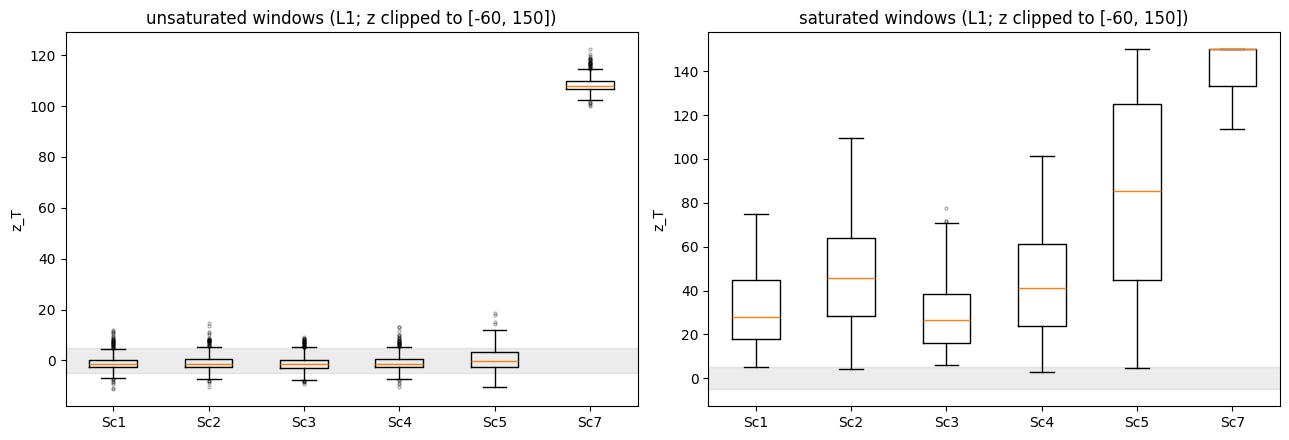

In [5]:
import matplotlib.pyplot as plt
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a_, (lab, m) in zip(ax, (("unsaturated windows", ~L.sat), ("saturated windows", L.sat))):
    data = [L[(L.scenario == sc) & m].z.clip(-60, 150).values for sc in SCN.values()]
    a_.boxplot([d if len(d) else [np.nan] for d in data], labels=list(SCN.values()), flierprops=dict(ms=2, alpha=.3))
    a_.axhspan(-5, 5, color="grey", alpha=.15); a_.set_title(lab + " (L1; z clipped to [-60, 150])"); a_.set_ylabel("z_T")
fig.tight_layout(); fig.savefig(FIGS / "11b_N3_zT.png", dpi=150); plt.show()


## 6. Interpretation

**The posterior extrapolates silently; a residual on the controlled variable flags it.** In unsaturated windows z_T separates the +2 K temperature-sensor drift (Sc7) from every well-specified scenario perfectly: AUC 1.000
(599 Sc7 windows against 3,031 Sc1–Sc5 windows, L1), median z_T +110 for Sc7 against a median of −0.7 to +1.5 in Sc1–Sc4, and every Sc7 window flagged at any threshold up to 20. With a threshold of 10 (the 99th percentile of
the unsaturated Sc1–Sc5 |z_T| is 9.7) the false-positive rate in Sc1–Sc5 unsaturated windows is 0.9% pooled (0.0–0.9% in Sc1–Sc4, 5.2% in Sc5). D1 and L1 agree (Sc7 flagged in 100% of windows).
The reason it works is the controller: with integral action the true temperature sits at the setpoint, so a sensor that reads +2 K shows up as a mean measured T 2 K away from T_sp, about 110 window-mean noise standard deviations. This is the
storyline's second half: **the failure is silent in the posterior (Sc7 coverage 0.002, notebook 11) but not silent in the data.**

**What the detector cannot do, and where it needs care.**
1. *Saturation.* The unguarded rule |z_T| > 5 flags 100% of the saturated windows in every scenario (the controller cannot hold T_sp, so T leaves the setpoint: that is a loss of control, not a sensor fault) and
   11% of the unsaturated Sc1–Sc4 windows (24% in Sc5): the threshold 5 assumes pure sensor noise and ignores the closed-loop transient. The rule is therefore two parts: flag saturation separately (Qc at the limit: a
   result is conditional on a plant that has lost control authority) and apply |z_T| > ≈ 10 only to unsaturated windows. Among saturated windows the statistic does not separate drift from no drift (Sc7 median z_T +150 against about +65 for Sc5);
   that is not tested further here.
2. *Only the controlled variable.* It sees an offset of T (the sensor in the loop) and nothing else: a drift of the concentration analyser, the coolant temperature sensor or the flow meter leaves T at T_sp. A drift of the
   T sensor smaller than about 10 noise standard deviations of the window mean (≈ 0.2 K) is not detected either; only Sc7's 2 K was tested. These limits belong in the checklist item.
3. *The threshold is calibrated on simulated healthy windows of this plant* (here the unsaturated Sc1–Sc5 windows of L1, the same data on which the 9.7 was read off); the checklist item is "calibrate the threshold on healthy simulated windows
   including the inlet variation", not "use 10".

**Checklist entry (for the storyline).** *Sensor-fault guard:* before trusting a posterior, compute z_T = (mean measured T − T_sp)/(σ_T/√n) on the window; if the valve is not saturated and |z_T| exceeds a threshold calibrated on healthy simulated windows (here ≈ 10), the
posterior is not to be used (an unmodelled offset on the controlled variable is present). If the valve is saturated, report that the loop has lost control and treat the result as conditional.

**Ledger.** Supports: Sc7 detection (100% in 1,000 + 50 windows, unsaturated AUC 1.0) at 0.9% false positives; documents: the 11% false-positive rate of the naive rule and the saturated-window ambiguity. Does not support: drift detection for sensors other than T, or for offsets
below ≈ 0.2 K.